# Bài 2 (trang 18-19) - Phân cụm Mall Customer bằng K-Means

**Sinh viên:** Nguyễn Đức Vinh  
**MSSV:** 6451071087

Khảo sát dữ liệu khách hàng, trực quan hóa phân phối và phân cụm bằng K-Means theo 2 thuộc tính và 3 thuộc tính, kết hợp Elbow và Silhouette.

> Chạy lần lượt các cell từ trên xuống dưới trong Google Colab. Mỗi notebook là một bài độc lập.

## 1. Thư viện và thông tin sinh viên

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

print("Nguyễn Đức Vinh - MSSV: 6451071087")

Nguyễn Đức Vinh - MSSV: 6451071087


## 2. Kết nối Google Drive và đọc dữ liệu Mall Customer (câu 1)

In [2]:
from pathlib import Path
import subprocess, sys, os

DRIVE_FOLDER_URL = "https://drive.google.com/drive/folders/11cbz4e_1jq89C6tpzwVZsHPYIrackRXB?usp=sharing"
DATA_DIR = Path("/content/lab3_dataset")

# Nếu chạy trên Colab, gắn Google Drive trước; đồng thời tải thư mục được chia sẻ bằng gdown.
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception:
    print("Không ở Google Colab hoặc không thể mount Drive; sẽ kiểm tra thư mục làm việc hiện tại.")

try:
    import gdown
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "-q", "install", "gdown"])
    import gdown

DATA_DIR.mkdir(parents=True, exist_ok=True)
try:
    gdown.download_folder(DRIVE_FOLDER_URL, output=str(DATA_DIR), quiet=False,
                          use_cookies=False, remaining_ok=True)
except Exception as exc:
    print("Không tải được thư mục Drive tự động:", exc)
    print("Hãy thêm shortcut thư mục chia sẻ vào MyDrive hoặc tải dữ liệu lên /content/lab3_dataset.")

# Tìm thêm trong MyDrive nếu thư mục dữ liệu đã được đồng bộ ở đó.
SEARCH_ROOTS = [DATA_DIR, Path("/content/drive/MyDrive")]

Mounted at /content/drive


Retrieving folder contents


Processing file 13qn-5-ccmFiPv4oPxcLxFol1KvRzk-L5 breast+cancer+wisconsin+diagnostic.zip
Processing file 1bsPcz8nZOMPcF3eVVs-EfmDRsqfjjUcC Mall_Customers.csv


Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=13qn-5-ccmFiPv4oPxcLxFol1KvRzk-L5
To: /content/lab3_dataset/breast+cancer+wisconsin+diagnostic.zip
100%|██████████| 51.3k/51.3k [00:00<00:00, 41.7MB/s]
Downloading...
From: https://drive.google.com/uc?id=1bsPcz8nZOMPcF3eVVs-EfmDRsqfjjUcC
To: /content/lab3_dataset/Mall_Customers.csv
100%|██████████| 3.98k/3.98k [00:00<00:00, 2.27MB/s]
Download completed


In [3]:
print("Nguyễn Đức Vinh - MSSV: 6451071087")
candidate_names = {"mall_customers.csv", "mall_customer3.csv", "mall_customers3.csv"}
csv_files = []
for root in SEARCH_ROOTS:
    if root.exists():
        csv_files.extend([p for p in root.rglob("*.csv")
                          if p.name.lower() in candidate_names or "mall" in p.name.lower()])

if not csv_files:
    raise FileNotFoundError(
        "Không tìm thấy CSV Mall Customer. Kiểm tra quyền chia sẻ thư mục Drive "
        "hoặc đặt file Mall_Customers.csv vào /content/lab3_dataset."
    )
DATA_PATH = csv_files[0]
print("File dữ liệu được sử dụng:", DATA_PATH)
df = pd.read_csv(DATA_PATH)
print("Kích thước ban đầu:", df.shape)
display(df.head())
print("Thông tin dữ liệu:")
df.info()
print("Số giá trị thiếu:")
display(df.isna().sum())

Nguyễn Đức Vinh - MSSV: 6451071087
File dữ liệu được sử dụng: /content/lab3_dataset/Mall_Customers.csv
Kích thước ban đầu: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


Thông tin dữ liệu:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB
Số giá trị thiếu:


,0
CustomerID,0
Gender,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0


In [4]:
print("Nguyễn Đức Vinh - MSSV: 6451071087")
# Chuẩn hóa tên cột để tương thích với các cách đặt tên phổ biến trong CSV.
def norm_col(name):
    return "".join(ch.lower() for ch in str(name) if ch.isalnum())

normalized = {norm_col(c): c for c in df.columns}
def find_column(keyword_options):
    for key, original in normalized.items():
        if any(opt in key for opt in keyword_options):
            return original
    return None

age_col = find_column(["age", "tuoi"])
income_col = find_column(["annualincome", "income"])
spending_col = find_column(["spendingscore", "spending", "diemmuasam"])
gender_col = find_column(["gender", "gioitinh"])
if not all([age_col, income_col, spending_col, gender_col]):
    raise ValueError(f"Không nhận diện đủ cột. Các cột hiện có: {list(df.columns)}")

work = df[[gender_col, age_col, income_col, spending_col]].copy()
work.columns = ["Gender", "Age", "Annual Income", "Spending Score"]
for col in ["Age", "Annual Income", "Spending Score"]:
    work[col] = pd.to_numeric(work[col], errors="coerce")
work["Gender"] = work["Gender"].fillna(work["Gender"].mode().iloc[0])
work[["Age", "Annual Income", "Spending Score"]] = SimpleImputer(strategy="median").fit_transform(
    work[["Age", "Annual Income", "Spending Score"]]
)
print("Kích thước sau xử lý:", work.shape)
display(work.describe().T)
display(work.isna().sum())

Nguyễn Đức Vinh - MSSV: 6451071087
Kích thước sau xử lý: (200, 4)


,count,mean,std,min,25%,50%,75%,max
Age,200.0,38.85,13.969007,18.0,28.75,36.0,49.0,70.0
Annual Income,200.0,60.56,26.264721,15.0,41.50,61.5,78.0,137.0
Spending Score,200.0,50.20,25.823522,1.0,34.75,50.0,73.0,99.0


,0
Gender,0
Age,0
Annual Income,0
Spending Score,0


## 3. Histogram cho Tuổi, Thu nhập và Spending Score (câu 2)

Nguyễn Đức Vinh - MSSV: 6451071087


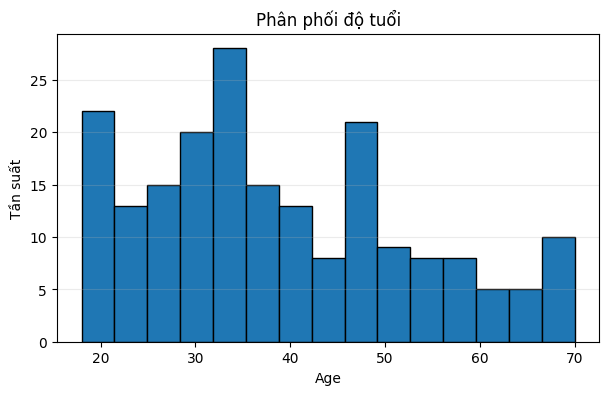

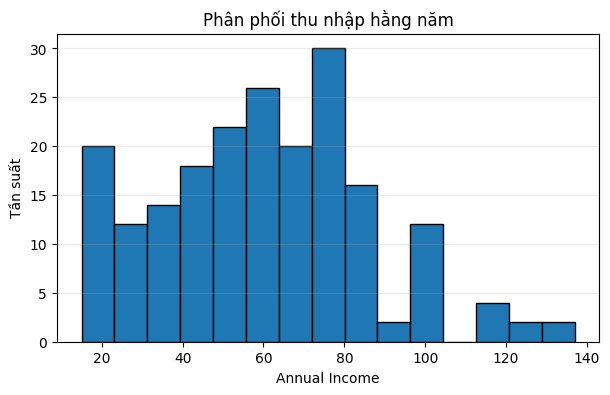

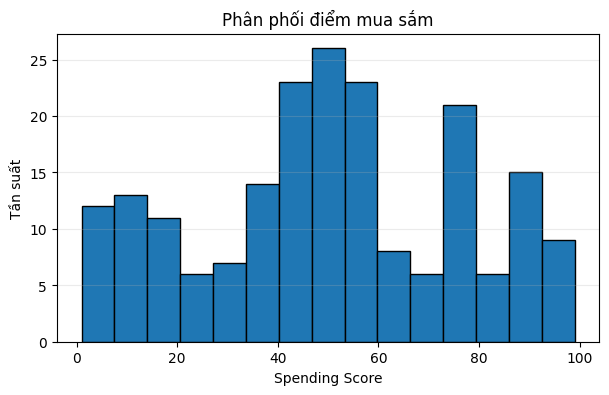

In [5]:
print("Nguyễn Đức Vinh - MSSV: 6451071087")
for column, title in [("Age", "Phân phối độ tuổi"),
                      ("Annual Income", "Phân phối thu nhập hằng năm"),
                      ("Spending Score", "Phân phối điểm mua sắm")]:
    plt.figure(figsize=(7, 4))
    plt.hist(work[column], bins=15, edgecolor="black")
    plt.xlabel(column)
    plt.ylabel("Tần suất")
    plt.title(title)
    plt.grid(axis="y", alpha=0.25)
    plt.show()

## 4. Thống kê số lượng mẫu theo giới tính (câu 3)

Nguyễn Đức Vinh - MSSV: 6451071087
Gender
Female    112
Male       88
Name: count, dtype: int64


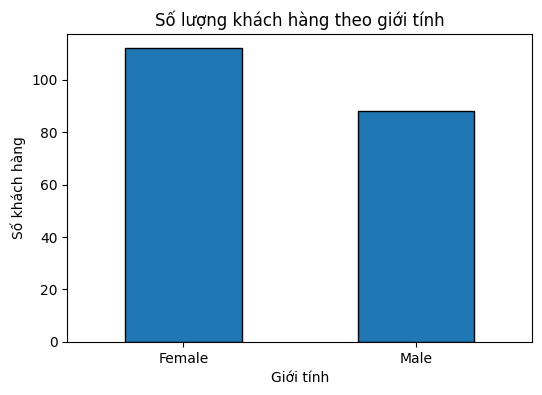

In [6]:
print("Nguyễn Đức Vinh - MSSV: 6451071087")
gender_counts = work["Gender"].value_counts()
print(gender_counts)
plt.figure(figsize=(6, 4))
gender_counts.plot(kind="bar", edgecolor="black")
plt.xlabel("Giới tính")
plt.ylabel("Số khách hàng")
plt.title("Số lượng khách hàng theo giới tính")
plt.xticks(rotation=0)
plt.show()

## 5. Scatter plot theo giới tính (câu 4, 5)

Nguyễn Đức Vinh - MSSV: 6451071087


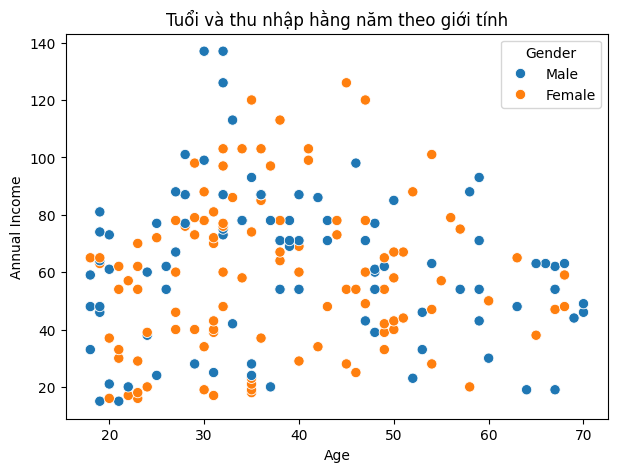

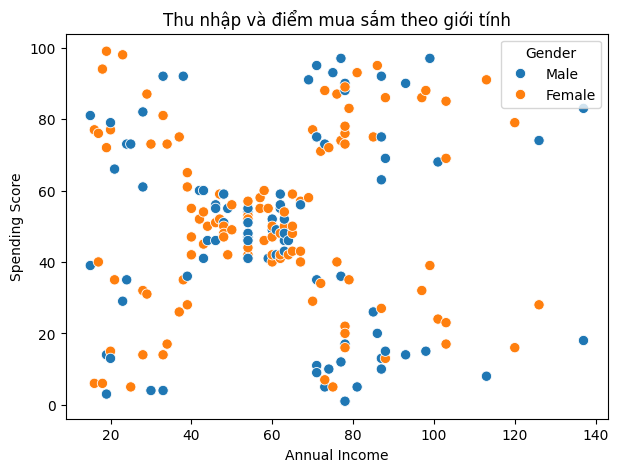

In [7]:
print("Nguyễn Đức Vinh - MSSV: 6451071087")
plt.figure(figsize=(7, 5))
sns.scatterplot(data=work, x="Age", y="Annual Income", hue="Gender", s=55)
plt.title("Tuổi và thu nhập hằng năm theo giới tính")
plt.show()

plt.figure(figsize=(7, 5))
sns.scatterplot(data=work, x="Annual Income", y="Spending Score", hue="Gender", s=55)
plt.title("Thu nhập và điểm mua sắm theo giới tính")
plt.show()

## 6. Hàm Elbow, K-Means và Silhouette (câu 6-9)

Nguyễn Đức Vinh - MSSV: 6451071087


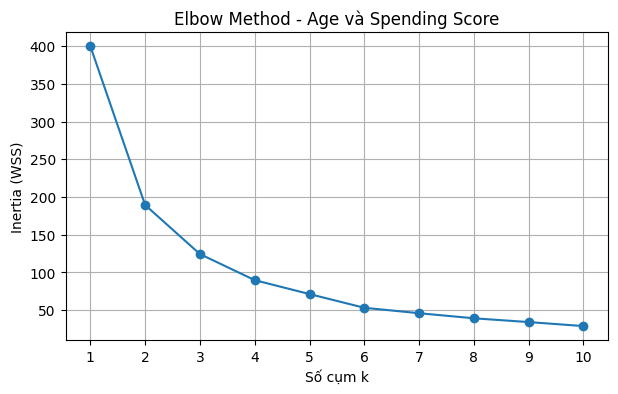

Số cụm được chọn theo điểm khuỷu tay: k=3
Silhouette coefficient: 0.4395


,Age,Spending Score,Cluster
0,28.714286,73.797619,0
1,56.080645,40.306452,1
2,34.833333,24.851852,2


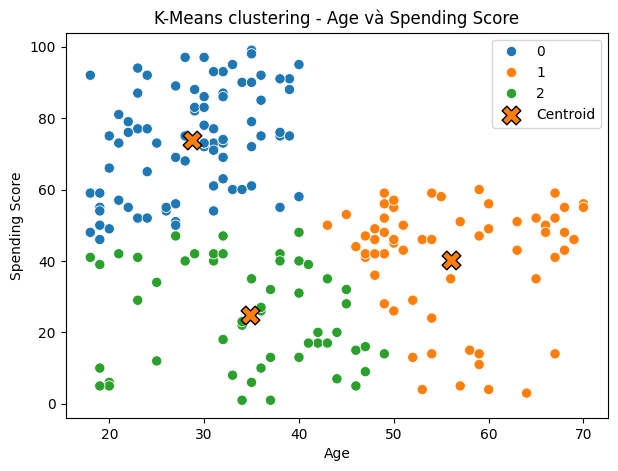

Số khách hàng trong từng cụm:


,Count
Cluster,
0,84
1,62
2,54


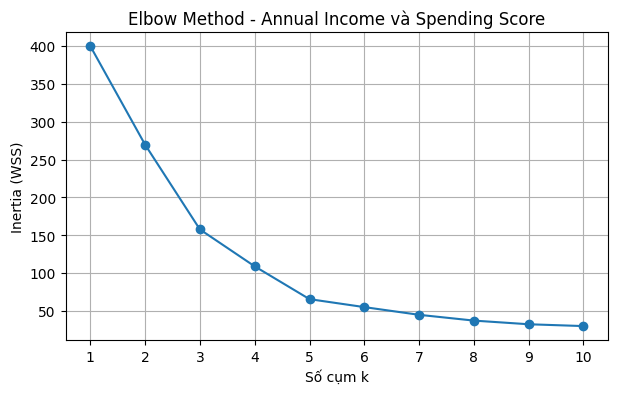

Số cụm được chọn theo điểm khuỷu tay: k=5
Silhouette coefficient: 0.5547


,Annual Income,Spending Score,Cluster
0,55.296296,49.518519,0
1,86.538462,82.128205,1
2,25.727273,79.363636,2
3,88.200000,17.114286,3
4,26.304348,20.913043,4


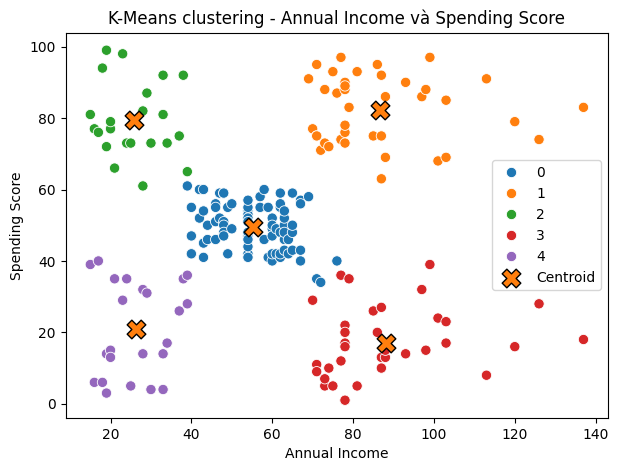

Số khách hàng trong từng cụm:


,Count
Cluster,
0,81
1,39
2,22
3,35
4,23


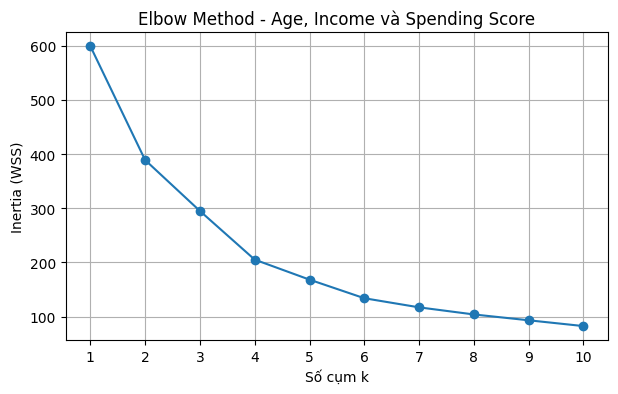

Số cụm được chọn theo điểm khuỷu tay: k=4
Silhouette coefficient: 0.404


,Age,Annual Income,Spending Score,Cluster
0,53.984615,47.707692,39.969231,0
1,32.875000,86.100000,81.525000,1
2,25.438596,40.000000,60.298246,2
3,39.368421,86.500000,19.578947,3


Số khách hàng trong từng cụm:


,Count
Cluster,
0,65
1,40
2,57
3,38


,Nhóm thuộc tính,k,Silhouette
0,Age + Spending Score,3,0.439530
1,Income + Spending Score,5,0.554657
2,Age + Income + Spending Score,4,0.403958


In [8]:
print("Nguyễn Đức Vinh - MSSV: 6451071087")
def elbow_k(inertias):
    # Chọn điểm xa nhất so với đường thẳng nối k nhỏ nhất và k lớn nhất.
    x = np.arange(len(inertias), dtype=float)
    x_norm = (x - x.min()) / (x.max() - x.min())
    y = np.asarray(inertias, dtype=float)
    y_norm = (y - y.min()) / (y.max() - y.min() + 1e-12)
    distance = np.abs(x_norm + y_norm - 1) / np.sqrt(2)
    return int(np.argmax(distance) + 1)

def cluster_experiment(columns, title, plot_3d=False):
    X_original = work[columns].to_numpy(dtype=float)
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_original)

    k_values = range(1, 11)
    inertias = []
    for k in k_values:
        km = KMeans(n_clusters=k, random_state=42, n_init=10)
        km.fit(X_scaled)
        inertias.append(km.inertia_)

    plt.figure(figsize=(7, 4))
    plt.plot(list(k_values), inertias, marker="o")
    plt.xlabel("Số cụm k")
    plt.ylabel("Inertia (WSS)")
    plt.title(f"Elbow Method - {title}")
    plt.xticks(list(k_values))
    plt.grid(True)
    plt.show()

    best_k = elbow_k(inertias)
    print(f"Số cụm được chọn theo điểm khuỷu tay: k={best_k}")
    model = KMeans(n_clusters=best_k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels,
                             sample_size=min(2000, len(X_scaled)),
                             random_state=42) if 2 <= len(np.unique(labels)) < len(labels) else np.nan
    print("Silhouette coefficient:", round(float(score), 4))

    result = work[columns].copy()
    result["Cluster"] = labels
    centers = scaler.inverse_transform(model.cluster_centers_)
    centers_df = pd.DataFrame(centers, columns=columns)
    centers_df["Cluster"] = np.arange(best_k)
    display(centers_df)

    if plot_3d:
        try:
            import plotly.express as px
        except ImportError:
            import subprocess, sys
            subprocess.check_call([sys.executable, "-m", "pip", "-q", "install", "plotly"])
            import plotly.express as px
        fig = px.scatter_3d(result, x=columns[0], y=columns[1], z=columns[2],
                            color=result["Cluster"].astype(str),
                            title=f"K-Means 3D - {title}")
        fig.show()
    else:
        plt.figure(figsize=(7, 5))
        sns.scatterplot(data=result, x=columns[0], y=columns[1],
                        hue="Cluster", palette="tab10", s=55)
        plt.scatter(centers[:, 0], centers[:, 1], marker="X", s=180,
                    edgecolor="black", label="Centroid")
        plt.title(f"K-Means clustering - {title}")
        plt.legend()
        plt.show()

    print("Số khách hàng trong từng cụm:")
    display(result["Cluster"].value_counts().sort_index().to_frame("Count"))
    return model, scaler, result, best_k, score

# Câu 6-8: Tuổi và Spending Score
model_age_spending, scaler_age_spending, result_age_spending, k_age_spending, sil_age_spending = cluster_experiment(
    ["Age", "Spending Score"], "Age và Spending Score"
)

# Câu 9a: Thu nhập và Spending Score
model_income_spending, scaler_income_spending, result_income_spending, k_income_spending, sil_income_spending = cluster_experiment(
    ["Annual Income", "Spending Score"], "Annual Income và Spending Score"
)

# Câu 9b: Tuổi, thu nhập và Spending Score
model_3d, scaler_3d, result_3d, k_3d, sil_3d = cluster_experiment(
    ["Age", "Annual Income", "Spending Score"], "Age, Income và Spending Score", plot_3d=True
)

summary = pd.DataFrame({
    "Nhóm thuộc tính": ["Age + Spending Score", "Income + Spending Score", "Age + Income + Spending Score"],
    "k": [k_age_spending, k_income_spending, k_3d],
    "Silhouette": [sil_age_spending, sil_income_spending, sil_3d]
})
display(summary)

## 7. Nhận xét

Qua kết quả thực nghiệm, K-Means đã phân chia khách hàng thành các nhóm khác nhau dựa trên đặc điểm tuổi, thu nhập và mức độ chi tiêu.
- Tuổi và Spending Score: Chọn k = 3, Silhouette = 0.4395, mức độ phân cụm tương đối.
- Annual Income và Spending Score: Chọn k = 5, Silhouette = 0.5547, cho kết quả phân cụm tốt nhất.
- Tuổi, Annual Income và Spending Score: Chọn k = 4, Silhouette = 0.4040, các cụm có mức độ phân tách thấp hơn.
Kết luận: Phân cụm theo Thu nhập hằng năm và Điểm mua sắm cho kết quả tốt nhất vì có hệ số Silhouette cao nhất. Điều này cho thấy hai thuộc tính này giúp phân biệt các nhóm khách hàng rõ ràng hơn.